# 05 - Multiple Linear Regression (MLR) Model

## Objective
Build and evaluate the Multiple Linear Regression model as a statistical baseline for predicting AI Adoption (SOP 4).

### Predictor Variables (X):
1. `ai_familiarity_score`
2. `perceived_usefulness_score`
3. `perceived_ease_of_use_score`
4. `trust_score`
5. `accessibility_score`
6. `digital_literacy_score`

### Target Variable (y):
- `ai_adoption_score`

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paths setup
cwd = Path.cwd()
project_candidates = [cwd, cwd.parent]
PROJECT_ROOT = next(
    (path for path in project_candidates if (path / "requirements.txt").is_file()),
    cwd,
)

DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
TABLES_DIR = RESULTS_DIR / "tables"
GRAPHS_DIR = RESULTS_DIR / "graphs"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
GRAPHS_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = DATA_DIR / "scored_data.csv"
print(f"Project root: {PROJECT_ROOT}")
print(f"Scored data path: {INPUT_PATH}")
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import RepeatedKFold, cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm


Project root: c:\Users\Marco Bautista\ai-adoption-analysis
Scored data path: c:\Users\Marco Bautista\ai-adoption-analysis\data\scored_data.csv


## Load Scored Dataset

In [3]:
if not INPUT_PATH.is_file():
    raise FileNotFoundError(
        f"Scored dataset not found at {INPUT_PATH}. Please run 02_scoring.ipynb first."
    )

df = pd.read_csv(INPUT_PATH)
print(f"Loaded {len(df)} respondents.")

feature_cols = [
    "ai_familiarity_score",
    "perceived_usefulness_score",
    "perceived_ease_of_use_score",
    "trust_score",
    "accessibility_score",
    "digital_literacy_score",
]
target_col = "ai_adoption_score"

X = df[feature_cols].copy()
y = df[target_col].copy()

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
display(X.head())


Loaded 100 respondents.
Features shape: (100, 6)
Target shape: (100,)


,ai_familiarity_score,perceived_usefulness_score,perceived_ease_of_use_score,trust_score,accessibility_score,digital_literacy_score
0,3.666667,4.000000,3.333333,2.333333,3.333333,4.333333
1,5.000000,5.000000,5.000000,3.666667,3.666667,4.666667
2,4.000000,4.000000,4.000000,3.333333,4.333333,3.666667
3,4.333333,2.333333,4.000000,1.000000,3.666667,3.333333
4,4.333333,4.666667,4.000000,3.666667,3.333333,4.000000


## OLS Regression Analysis & Coefficients

In [4]:
X_sm = sm.add_constant(X)
ols_model = sm.OLS(y, X_sm).fit()
print(ols_model.summary())

coef_df = pd.DataFrame({
    "Variable": ols_model.params.index,
    "Coefficient (B)": ols_model.params.values,
    "Std Error": ols_model.bse.values,
    "t-value": ols_model.tvalues.values,
    "p-value": ols_model.pvalues.values
})
coef_path = TABLES_DIR / "mlr_coefficients.csv"
coef_df.to_csv(coef_path, index=False)
print(f"Regression coefficients saved to: {coef_path}")

                            OLS Regression Results                            
Dep. Variable:      ai_adoption_score   R-squared:                       0.251
Model:                            OLS   Adj. R-squared:                  0.202
Method:                 Least Squares   F-statistic:                     5.188
Date:                Sat, 21 Nov 2026   Prob (F-statistic):           0.000121
Time:                        06:56:41   Log-Likelihood:                -116.05
No. Observations:                 100   AIC:                             246.1
Df Residuals:                      93   BIC:                             264.3
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
const             

## Cross-Validation Performance

We evaluate MLR using the exact same repeated 5-fold cross-validation procedure (10 repeats, random_state=42).

In [5]:
mlr = LinearRegression()
rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)

cv_results = cross_validate(
    mlr,
    X,
    y,
    cv=rkf,
    scoring={
        "neg_rmse": "neg_root_mean_squared_error",
        "neg_mae": "neg_mean_absolute_error",
        "r2": "r2",
    },
    return_train_score=False,
)

rmse_scores = -cv_results["test_neg_rmse"]
mae_scores = -cv_results["test_neg_mae"]
r2_scores = cv_results["test_r2"]

mlr_metrics_df = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2"],
    "Mean": [rmse_scores.mean(), mae_scores.mean(), r2_scores.mean()],
    "Std": [rmse_scores.std(), mae_scores.std(), r2_scores.std()],
})
display(mlr_metrics_df)

mlr_results_path = TABLES_DIR / "regression_results.csv"
mlr_metrics_df.to_csv(mlr_results_path, index=False)
print(f"MLR CV performance saved to: {mlr_results_path}")

,Metric,Mean,Std
0,RMSE,0.854553,0.154297
1,MAE,0.658411,0.097754
2,R2,-0.052573,0.523378


MLR CV performance saved to: c:\Users\Marco Bautista\ai-adoption-analysis\results\tables\regression_results.csv


## Predicted vs Actual Plot

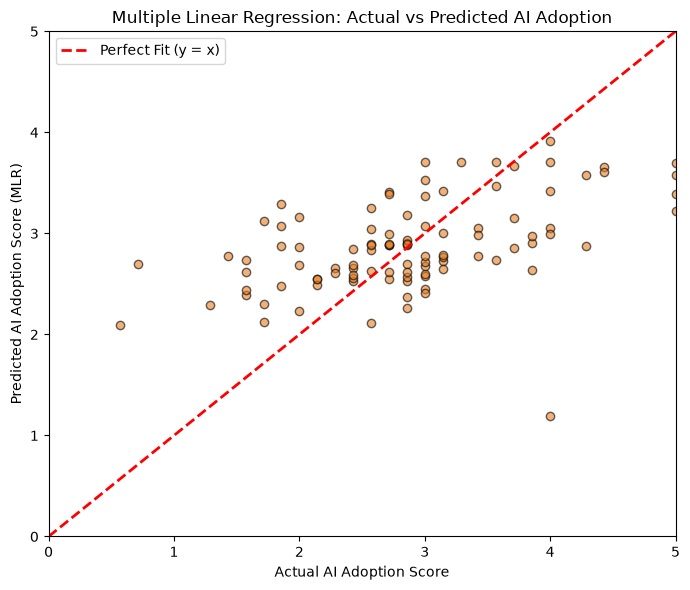

Plot saved to: c:\Users\Marco Bautista\ai-adoption-analysis\results\graphs\regression_actual_vs_predicted.png


In [6]:
mlr.fit(X, y)
y_pred = mlr.predict(X)

plt.figure(figsize=(7, 6))
plt.scatter(y, y_pred, alpha=0.6, edgecolors="k", color="#e67e22")
plt.plot([0, 5], [0, 5], "r--", lw=2, label="Perfect Fit (y = x)")
plt.xlabel("Actual AI Adoption Score")
plt.ylabel("Predicted AI Adoption Score (MLR)")
plt.title("Multiple Linear Regression: Actual vs Predicted AI Adoption")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.legend()
plt.tight_layout()

mlr_graph_path = GRAPHS_DIR / "regression_actual_vs_predicted.png"
plt.savefig(mlr_graph_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()
print(f"Plot saved to: {mlr_graph_path}")